# SCOPe family assignment benchmark

## Description

Using viral subset of the SCOPe dataset, we assess the performance of ESM3Di versus ProstT5 in assigning domains to the correct category.

This is a reproduced version of the identical benchmark used in Foldseek paper, therefore please refer to the paper ([link](https://www.nature.com/articles/s41587-023-01773-0)) for detailed description of the benchmark (Methods - SCOPe benchmark).

---

## SCOPe Dataset preparation

### Download SCOPe40 dataset

In [1]:
from pathlib import Path
import os

DATAPATH = Path("/scratch/fweikert/data/scope_benchmark")
DATAPATH.mkdir(parents=True, exist_ok=True)

os.environ["DATAPATH"] = str(DATAPATH)
print(f"DATAPATH set to: {DATAPATH}")

DATAPATH set to: /scratch/fweikert/data/scope_benchmark


In [4]:
%%bash

mkdir -p $DATAPATH/scope

wget --no-check-certificate -q -O $DATAPATH/scope/dir.des.scope.txt \
	"https://scop.berkeley.edu/downloads/parse/dir.des.scope.2.08-stable.txt"
wget --no-check-certificate -q -O $DATAPATH/scope/dir.cla.scope.txt \
	"https://scop.berkeley.edu/downloads/parse/dir.cla.scope.2.08-stable.txt"

### Parse taxonomy information to obtain viral subset of the SCOPe dataset

#### Obtain NCBI taxdump files

In [5]:
%%bash
mkdir -p $DATAPATH/ncbi
wget -q -O $DATAPATH/ncbi/taxdump.tar.gz "ftp://ftp.ncbi.nih.gov/pub/taxonomy/taxdump.tar.gz"
tar -xzf $DATAPATH/ncbi/taxdump.tar.gz -C $DATAPATH/ncbi

#### Parse taxonomy files and identify viral entries

In [6]:
%%bash
awk -F'\t' '$7~/scientific/' $DATAPATH/ncbi/names.dmp > $DATAPATH/ncbi/scientific_names.dmp
awk '\
	BEGIN{FS="\t"; OFS="\t"} FNR==1{FC++} \
	FC==1{p[$1]=$3;r[$1]=$5;next} \
	FC==2{n[$1]=$3;next} \
	{x="";while($2>1){x=x?n[$2]","x:n[$2];$2=p[$2]} print $1,x}' \
	$DATAPATH/ncbi/nodes.dmp $DATAPATH/ncbi/scientific_names.dmp \
	<(awk -F'\t|=|,| |]' 'NR==FNR{if($2=="sp")f[$1]=$(NF-1);next} FNR>4 {print $1 "\t" f[$17]}' \
	$DATAPATH/scope/dir.des.scope.txt $DATAPATH/scope/dir.cla.scope.txt) \
	> $DATAPATH/scope/scope40_taxonomy.tsv
awk -F'\t|,' '$2~/Viruses/ {print $1}' $DATAPATH/scope/scope40_taxonomy.tsv > $DATAPATH/scope/scope40_viral_ids.txt
echo "$(wc -l < $DATAPATH/scope/scope40_viral_ids.txt) viral entries identified in the SCOPe40 dataset"

16272 viral entries identified in the SCOPe40 dataset


### Create viral subset of the SCOPe40 dataset

#### Download PDB files

In [7]:
%%bash

mkdir -p $DATAPATH/scope/pdb_viral


In [8]:
%%bash
cat $DATAPATH/scope/scope40_viral_ids.txt | while read id; do
	echo -e "https://scop.berkeley.edu/downloads/pdbstyle/pdbstyle-2.08/${id:2:2}/${id}.ent\n\tout=pdb_viral/${id}.pdb"
done > $DATAPATH/scope/scope40_aria2c.txt



In [9]:
%%bash
#read some lines from the aria2c input file to verify the format

head -n 10 $DATAPATH/scope/scope40_aria2c.txt

https://scop.berkeley.edu/downloads/pdbstyle/pdbstyle-2.08/ez/d2ezla_.ent
	out=pdb_viral/d2ezla_.pdb
https://scop.berkeley.edu/downloads/pdbstyle/pdbstyle-2.08/ez/d2ezka_.ent
	out=pdb_viral/d2ezka_.pdb
https://scop.berkeley.edu/downloads/pdbstyle/pdbstyle-2.08/ez/d2ezia_.ent
	out=pdb_viral/d2ezia_.pdb
https://scop.berkeley.edu/downloads/pdbstyle/pdbstyle-2.08/ez/d2ezha_.ent
	out=pdb_viral/d2ezha_.pdb
https://scop.berkeley.edu/downloads/pdbstyle/pdbstyle-2.08/h8/d1h8ac1.ent
	out=pdb_viral/d1h8ac1.pdb


In [10]:
%%bash
cd $DATAPATH/scope
aria2c -i $DATAPATH/scope/scope40_aria2c.txt -x 16 -j 16 --check-certificate=false --quiet=false


10/19 09:19:24 [NOTICE] Downloading 16272 item(s)

10/19 09:19:25 [NOTICE] Download complete: /scratch/fweikert/data/scope_benchmark/scope/pdb_viral/d1h8ac1.pdb

10/19 09:19:25 [NOTICE] Download complete: /scratch/fweikert/data/scope_benchmark/scope/pdb_viral/d1h8ac2.pdb

10/19 09:19:25 [NOTICE] Download complete: /scratch/fweikert/data/scope_benchmark/scope/pdb_viral/d2ezha_.pdb

10/19 09:19:25 [NOTICE] Download complete: /scratch/fweikert/data/scope_benchmark/scope/pdb_viral/d1rr7a_.pdb

10/19 09:19:25 [NOTICE] Download complete: /scratch/fweikert/data/scope_benchmark/scope/pdb_viral/d1bjaa_.pdb

10/19 09:19:25 [NOTICE] Download complete: /scratch/fweikert/data/scope_benchmark/scope/pdb_viral/d1sfua_.pdb

10/19 09:19:25 [NOTICE] Download complete: /scratch/fweikert/data/scope_benchmark/scope/pdb_viral/d1bjab_.pdb

10/19 09:19:25 [NOTICE] Download complete: /scratch/fweikert/data/scope_benchmark/scope/pdb_viral/d1ka8b_.pdb

10/19 09:19:25 [NOTICE] Download complete: /scratch/fweikert

In [11]:
%%bash
#count the number of viral entries with successfully downloaded PDB files
find $DATAPATH/scope/pdb_viral/ -maxdepth 1 -type f -print | wc -l

16272


#### Remove entries with multiple models

In [12]:
%%bash
mkdir -p $DATAPATH/scope/pdb_viral_multi
cat $DATAPATH/scope/scope40_viral_ids.txt | while read id; do
	CNT=$(grep -m2 MODEL $DATAPATH/scope/pdb_viral/${id}.pdb | wc -l)
	# if count is greater than 1, move the file to a separate folder
	if [ $CNT -gt 1 ]; then
		mv $DATAPATH/scope/pdb_viral/${id}.pdb $DATAPATH/scope/pdb_viral_multi/${id}.pdb
	fi
done

In [13]:
%%bash
mkdir -p $DATAPATH/foldseek
foldseek createdb $DATAPATH/scope/pdb_viral $DATAPATH/foldseek/scope40_viral

createdb /scratch/fweikert/data/scope_benchmark/scope/pdb_viral /scratch/fweikert/data/scope_benchmark/foldseek/scope40_viral 

MMseqs Version:             	10.941cd33
Use GPU                     	0
Path to ProstT5             	
Chain name mode             	0
Createdb extraction mode    	0
Interface distance threshold	8
Write mapping file          	0
Mask b-factor threshold     	0
Coord store mode            	2
Write lookup file           	1
Input format                	0
File Inclusion Regex        	.*
File Exclusion Regex        	^$
Threads                     	48
Verbosity                   	3

Output file: /scratch/fweikert/data/scope_benchmark/foldseek/scope40_viral
[=================================================================] 15.97K 19s 762ms
Time for merging to scope40_viral_ss: 0h 0m 0s 19ms
Time for merging to scope40_viral_h: 0h 0m 0s 19ms
Time for merging to scope40_viral_ca: 0h 0m 0s 49ms
Time for merging to scope40_viral: 0h 0m 0s 32ms
Ignore 3 out of 15969.
Too shor

### Create FASTA files of the viral SCOPe40 dataset

In [14]:
%%bash
foldseek base:convert2fasta $DATAPATH/foldseek/scope40_viral $DATAPATH/scope/scope40_viral_aa.fa
foldseek base:lndb $DATAPATH/foldseek/scope40_viral_h $DATAPATH/foldseek/scope40_viral_ss_h
foldseek base:convert2fasta $DATAPATH/foldseek/scope40_viral_ss $DATAPATH/scope/scope40_viral_3di.fa

convert2fasta /scratch/fweikert/data/scope_benchmark/foldseek/scope40_viral /scratch/fweikert/data/scope_benchmark/scope/scope40_viral_aa.fa 

MMseqs Version:	10.941cd33
Use header DB	false
Verbosity    	3

Start writing file to /scratch/fweikert/data/scope_benchmark/scope/scope40_viral_aa.fa
Time for processing: 0h 0m 0s 10ms
lndb /scratch/fweikert/data/scope_benchmark/foldseek/scope40_viral_h /scratch/fweikert/data/scope_be

nchmark/foldseek/scope40_viral_ss_h 

MMseqs Version:	10.941cd33
Verbosity	3

Time for processing: 0h 0m 0s 0ms
convert2fasta /scratch/fweikert/data/scope_benchmark/foldseek/scope40_viral_ss /scratch/fweikert/data/scope_benchmark/scope/scope40_viral_3di.fa 

MMseqs Version:	10.941cd33
Use header DB	false
Verbosity    	3

Start writing file to /scratch/fweikert/data/scope_benchmark/scope/scope40_viral_3di.fa
Time for processing: 0h 0m 0s 10ms


In [15]:
# from fasta file compute length distribution of sequences
import matplotlib.pyplot as plt
from Bio import SeqIO
import pandas as pd

fasta_path = DATAPATH / "scope/scope40_viral_aa.fa"
# Load the FASTA file
records = list(SeqIO.parse(fasta_path, "fasta"))

# Compute sequence lengths
lengths = [len(record) for record in records]

# Plot the length distribution
pd.Series(lengths).describe().to_frame().T  # Show summary statistics

,count,mean,std,min,25%,50%,75%,max
0,15966.0,222.935049,129.370287,14.0,129.0,172.0,306.0,1284.0


---

## 3Di prediction with ProstT5 and ESM3Di

#### Predict 3Di with ProstT5

In [18]:
%%bash
foldseek databases ProstT5 $DATAPATH/prostt5_weights $DATAPATH/tmp
rm -rf $DATAPATH/tmp
foldseek createdb $DATAPATH/scope/scope40_viral_aa.fa $DATAPATH/foldseek/scope40_viral_prostt5 --gpu 1 --prostt5-model $DATAPATH/prostt5_weights

/scratch/fweikert/data/scope_benchmark/prostt5_weights exists and will be overwritten
Create directory /scratch/fweikert/data/scope_benchmark/tmp
databases ProstT5 /scratch/fweikert/data/scope_benchmark/prostt5_weights /scratch/fweikert/data/scope_benchmark/tmp 

MMseqs Version:              	10.941cd33
Tsv                          	false
Force restart with latest tmp	false
Remove temporary files       	false
Compressed                   	0
Threads                      	48
Verbosity                    	3


10/19 09:27:35 [NOTICE] Downloading 1 item(s)

10/19 09:27:36 [ERROR] CUID#7 - Download aborted. URI=https://foldseek.steineggerlab.workers.dev/prostt5-f16-gguf.tar.gz
Exception: [AbstractCommand.cc:351] errorCode=22 URI=https://foldseek.steineggerlab.workers.dev/prostt5-f16-gguf.tar.gz
  -> [HttpSkipResponseCommand.cc:239] errorCode=22 The response status is not successful. status=429

10/19 09:27:36 [NOTICE] Download GID#a6e4c2d6bd8b6341 not complete: /scratch/fweikert/data/scope_b

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
1 0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     000    17  100    17    0     0    188      0 --:--:-- --:--:-- --:--:--   188

gzip: stdin: not in gzip format
tar: Child returned status 1
tar: Error is not recoverable: exiting now


/scratch/fweikert/data/scope_benchmark/foldseek/scope40_viral_prostt5 exists and will be overwritten
/scratch/fweikert/data/scope_benchmark/foldseek/scope40_viral_prostt5 exists and will be overwritten
createdb /scratch/fweikert/data/scope_benchmark/scope/scope40_viral_aa.fa /scratch/fweikert/data/scope_benchmark/foldseek/scope40_viral_prostt5 --gpu 1 --prostt5-model /scratch/fweikert/data/scope_benchmark/prostt5_weights 

MMseqs Version:             	10.941cd33
Use GPU                     	1
Path to ProstT5             	/scratch/fweikert/data/scope_benchmark/prostt5_weights
Chain name mode             	0
Createdb extraction mode    	0
Interface distance threshold	8
Write mapping file          	0
Mask b-factor threshold     	0
Coord store mode            	2
Write lookup file           	1
Input format                	0
File Inclusion Regex        	.*
File Exclusion Regex        	^$
Threads                     	48
Verbosity                   	3

Converting sequences
[=
Time for merging t

### Predict 3Di representations with ESM3Di

In [19]:
%%bash
set -euo pipefail

esm3di foldseek-db \
    --input-fasta "$DATAPATH/scope/scope40_viral_aa.fa" \
    --output-db "$DATAPATH/foldseek/scope40_viral_esm3di" \
    --batch-size 16

10:06:48 [INFO] Using cached model 'cactuskid13/ESM3di_Small_MLM_3di' from local Hugging Face cache.
10:06:50 [INFO] Using device: cuda (NVIDIA A100-PCIE-40GB MIG 3g.20gb)
10:11:19 [INFO] Building Foldseek database at: /scratch/fweikert/data/scope_benchmark/foldseek/scope40_viral_esm3di
10:11:19 [INFO] Foldseek database generated successfully.


## Foldseek search and parsing results

### Target 1. ProstT5

#### All-vs-all Foldseek search

In [2]:
%%bash
foldseek search --exhaustive-search -e INF \
	$DATAPATH/foldseek/scope40_viral_prostt5 $DATAPATH/foldseek/scope40_viral \
	$DATAPATH/foldseek/scope40_viral_prostt5_aln $DATAPATH/tmp
foldseek convertalis --format-output query,target \
	$DATAPATH/foldseek/scope40_viral_prostt5 $DATAPATH/foldseek/scope40_viral \
	$DATAPATH/foldseek/scope40_viral_prostt5_aln $DATAPATH/scope/scope40_viral_prostt5_aln.tsv

search --exhaustive-search -e INF /scratch/fweikert/data/scop_benchmark/foldseek/scope40_viral_prostt5 /scratch/fweikert/data/scop_benchmark/foldseek/scope40_viral /scratch/fweikert/data/scop_benchmark/foldseek/scope40_viral_prostt5_aln /scratch/fweikert/data/scop_benchmark/tmp 

MMseqs Version:                    	10.941cd33
Seq. id. threshold                 	0
Coverage threshold                 	0
Coverage mode                      	0
Max reject                         	2147483647
Max accept                         	2147483647
Add backtrace                      	false
TMscore threshold                  	0
TMscore threshold mode             	0
TMalign hit order                  	0
TMalign fast                       	1
Preload mode                       	0
Threads                            	48
Verbosity                          	3
LDDT threshold                     	0
Sort by structure bit score        	1
Alignment type                     	2
Exact TMscore                      	0
Sub

#### Calculate fraction of correct assignments up to first false positive

In [2]:
import polars as pl

def calc_fp_rates(aln_class_path, method_name):
	inp = pl.read_csv(
		aln_class_path,
		separator='\t',
		has_header=False,
		new_columns=['qid', 'tid', 'qfo', 'qsf', 'qfa', 'tfo', 'tsf', 'tfa'],
	)

	# 1) assign distance along each query group
	inp = inp.with_columns([
		pl.arange(0, pl.len()).over('qid').alias('rid'),
	])

	# 2) convert condition to numeric status
	inp = inp.with_columns([
		(pl.col('qfo') != pl.col('tfo')).cast(pl.Int8).alias('is_wrong_fold'),
		(pl.col('qfo') == pl.col('tfo')).cast(pl.Int8).alias('is_same_fold'),
		(pl.col('qsf') == pl.col('tsf')).cast(pl.Int8).alias('is_same_super'),
		(pl.col('qfa') == pl.col('tfa')).cast(pl.Int8).alias('is_same_family'),
	])

	# 3) compute overflow flag: true once wrong fold seen for each query
	inp = inp.with_columns([
		(pl.col('is_wrong_fold').cum_sum().over('qid').gt(0)).cast(pl.Int8).alias('seen_fp'),
	])

	# 4) compute per-hit classes
	inp = inp.with_columns([
		((pl.col('qfo') == pl.col('tfo')) & (pl.col('qsf') != pl.col('tsf'))).cast(pl.Int32).alias('count_fold'),
		((pl.col('qfo') == pl.col('tfo')) & (pl.col('qsf') == pl.col('tsf')) & (pl.col('qfa') != pl.col('tfa'))).cast(pl.Int32).alias('count_super'),
		((pl.col('qfo') == pl.col('tfo')) & (pl.col('qsf') == pl.col('tsf')) & (pl.col('qfa') == pl.col('tfa'))).cast(pl.Int32).alias('count_family'),
	])

	# 5) fold/super/fam if not FP-flagged for this row
	inp = inp.with_columns([
		(pl.col('count_fold') * (1 - pl.col('seen_fp'))).alias('fold_tp'),
		(pl.col('count_super') * (1 - pl.col('seen_fp'))).alias('super_tp'),
		(pl.col('count_family') * (1 - pl.col('seen_fp'))).alias('family_tp'),
	])

	# aggregates per qid
	agg = inp.group_by('qid', maintain_order=True).agg([
		pl.col('fold_tp').sum().alias('focnt'),
		pl.col('count_fold').sum().alias('fotot'),
		pl.col('super_tp').sum().alias('sfcnt'),
		pl.col('count_super').sum().alias('sftot'),
		pl.col('family_tp').sum().alias('facnt'),
		pl.col('count_family').sum().alias('fatot'),
	])

	agg = agg.with_columns([
		pl.when(pl.col('fotot') == 0).then(1).otherwise(pl.col('fotot')).alias('fotot'),
		pl.when(pl.col('sftot') == 0).then(1).otherwise(pl.col('sftot')).alias('sftot'),
		pl.when(pl.col('fatot') == 0).then(1).otherwise(pl.col('fatot')).alias('fatot'),
	])

	agg = agg.with_columns([
		(pl.col('focnt') / pl.col('fotot')).alias('fofrac'),
		(pl.col('sfcnt') / pl.col('sftot')).alias('sfrac'),
		(pl.col('facnt') / pl.col('fatot')).alias('fafrac'),
	])

	agg.select(['qid', 'focnt', 'fotot', 'fofrac']).write_csv(str(DATAPATH / f'scope/{method_name}_fol.tsv'), separator='\t', include_header=False)
	agg.select(['qid', 'sfcnt', 'sftot', 'sfrac']).write_csv(str(DATAPATH / f'scope/{method_name}_sup.tsv'), separator='\t', include_header=False)
	agg.select(['qid', 'facnt', 'fatot', 'fafrac']).write_csv(str(DATAPATH / f'scope/{method_name}_fam.tsv'), separator='\t', include_header=False)



### Target 2. Foldseek

#### All-vs-all Foldseek search

In [3]:
%%bash
foldseek search --exhaustive-search -e INF \
	$DATAPATH/foldseek/scope40_viral $DATAPATH/foldseek/scope40_viral \
	$DATAPATH/foldseek/scope40_viral_foldseek_aln $DATAPATH/tmp
foldseek convertalis --format-output query,target \
	$DATAPATH/foldseek/scope40_viral $DATAPATH/foldseek/scope40_viral \
	$DATAPATH/foldseek/scope40_viral_foldseek_aln $DATAPATH/scope/scope40_viral_foldseek_aln.tsv

search --exhaustive-search -e INF /scratch/fweikert/data/scop_benchmark/foldseek/scope40_viral /scratch/fweikert/data/scop_benchmark/foldseek/scope40_viral /scratch/fweikert/data/scop_benchmark/foldseek/scope40_viral_foldseek_aln /scratch/fweikert/data/scop_benchmark/tmp 

MMseqs Version:                    	10.941cd33
Seq. id. threshold                 	0
Coverage threshold                 	0
Coverage mode                      	0
Max reject                         	2147483647
Max accept                         	2147483647
Add backtrace                      	false
TMscore threshold                  	0
TMscore threshold mode             	0
TMalign hit order                  	0
TMalign fast                       	1
Preload mode                       	0
Threads                            	48
Verbosity                          	3
LDDT threshold                     	0
Sort by structure bit score        	1
Alignment type                     	2
Exact TMscore                      	0
Substituti

### Target 3. MMseqs2

#### All-vs-all MMseqs2 search

In [2]:
%%bash
# create fake prefilter file
foldseek base:tsv2db --output-dbtype 7 \
	<(awk 'END {for(i=0;i<NR;i++) for(j=0;j<NR;j++) print i "\t" j}' $DATAPATH/foldseek/scope40_viral.index) \
	$DATAPATH/foldseek/scope40_viral_mmseqs_pref
foldseek base:align -e INF \
	$DATAPATH/foldseek/scope40_viral $DATAPATH/foldseek/scope40_viral \
	$DATAPATH/foldseek/scope40_viral_mmseqs_pref \
	$DATAPATH/foldseek/scope40_viral_mmseqs_aln
foldseek base:convertalis --format-output query,target \
	$DATAPATH/foldseek/scope40_viral $DATAPATH/foldseek/scope40_viral \
	$DATAPATH/foldseek/scope40_viral_mmseqs_aln $DATAPATH/scope/scope40_viral_mmseqs_aln.tsv

tsv2db --output-dbtype 7 /dev/fd/63 /scratch/fweikert/data/scop_benchmark/foldseek/scope40_viral_mmseqs_pref 

MMseqs Version:           	10.941cd33
Output database type      	7
Compressed                	0
Verbosity                 	3

Output database type: Prefilter
Time for merging to scope40_viral_mmseqs_pref: 0h 0m 0s 3ms
Time for processing: 0h 1m 32s 185ms
align -e INF /scratch/fweikert/data/scop_benchmark/foldseek/scope40_viral /scratch/fweikert/data/scop_benchmark/foldseek/scope40_viral /scratch/fweikert/data/scop_benchmark/foldseek/scope40_viral_mmseqs_pref /scratch/fweikert/data/scop_benchmark/foldseek/scope40_viral_mmseqs_aln 

MMseqs Version:           	10.941cd33
Substitution matrix       	aa:3di.out,nucl:3di.out
Add backtrace             	false
Alignment mode            	0
Alignment mode            	0
E-value threshold         	inf
Seq. id. threshold        	0
Min alignment length      	0
Seq. id. mode             	0
Alternative alignments    	0
Coverage threshold       

### Target 4. ESM3Di



In [3]:
%%bash
foldseek search --exhaustive-search -e INF \
	$DATAPATH/foldseek/scope40_viral_esm3di $DATAPATH/foldseek/scope40_viral_esm3di \
	$DATAPATH/foldseek/scope40_viral_esm3di_aln $DATAPATH/tmp
foldseek convertalis --format-output query,target \
	$DATAPATH/foldseek/scope40_viral_esm3di $DATAPATH/foldseek/scope40_viral_esm3di \
	$DATAPATH/foldseek/scope40_viral_esm3di_aln $DATAPATH/scope/scope40_viral_esm3di_aln.tsv

search --exhaustive-search -e INF /scratch/fweikert/data/scop_benchmark/foldseek/scope40_viral_esm3di /scratch/fweikert/data/scop_benchmark/foldseek/scope40_viral_esm3di /scratch/fweikert/data/scop_benchmark/foldseek/scope40_viral_esm3di_aln /scratch/fweikert/data/scop_benchmark/tmp 

MMseqs Version:                    	10.941cd33
Seq. id. threshold                 	0
Coverage threshold                 	0
Coverage mode                      	0
Max reject                         	2147483647
Max accept                         	2147483647
Add backtrace                      	false
TMscore threshold                  	0
TMscore threshold mode             	0
TMalign hit order                  	0
TMalign fast                       	1
Preload mode                       	0
Threads                            	48
Verbosity                          	3
LDDT threshold                     	0
Sort by structure bit score        	1
Alignment type                     	2
Exact TMscore                      	

structurealign /scratch/fweikert/data/scop_benchmark/foldseek/scope40_viral_esm3di /scratch/fweikert/data/scop_benchmark/foldseek/scope40_viral_esm3di /scratch/fweikert/data/scop_benchmark/tmp/10793283378458350226/pref /scratch/fweikert/data/scop_benchmark/tmp/10793283378458350226/strualn --tmscore-threshold 0 --tmscore-threshold-mode 0 --lddt-threshold 0 --sort-by-structure-bits 1 --alignment-type 2 --exact-tmscore 0 --sub-mat 'aa:3di.out,nucl:3di.out' -a 0 --alignment-mode 3 --alignment-output-mode 0 --wrapped-scoring 0 -e inf --min-seq-id 0 --min-aln-len 0 --seq-id-mode 0 --alt-ali 0 -c 0 --cov-mode 0 --max-seq-len 65535 --comp-bias-corr 1 --comp-bias-corr-scale 0.5 --max-rejected 2147483647 --max-accept 2147483647 --add-self-matches 0 --db-load-mode 0 --pca substitution:1.100,context:1.400 --pcb substitution:4.100,context:5.800 --score-bias 0 --realign 0 --realign-score-bias -0.2 --realign-max-seqs 2147483647 --corr-score-weight 0 --gap-open aa:10,nucl:10 --gap-extend aa:1,nucl:1 -

#### Assign fold/superfamily/family information

In [3]:
import polars as pl

# load SCOPe class map and skip the 4-line header from dir.cla.scope.txt
cla = pl.read_csv(
	DATAPATH / 'scope/dir.cla.scope.txt',
	separator='\t',
	has_header=False,
	new_columns=['id', 'parent', 'something', 'class'],
	skip_rows=4,
)

cla = cla.with_columns([
	pl.col('class').str.split('.').list.get(1).alias('fo'),
	pl.col('class').str.split('.').list.get(2).alias('sf'),
	pl.col('class').str.split('.').list.get(3).alias('fa'),
])

cla = cla.select(['id', 'fo', 'sf', 'fa'])

# function to make classified alignment table
def compute_aln_class(aln_tsv, output_tsv):
	aln = pl.read_csv(
		aln_tsv,
		separator='\t',
		has_header=False,
		new_columns=['qid', 'tid'],
	)
	work = aln.join(cla, left_on='qid', right_on='id', how='left')
	work = work.rename({'fo':'qfo', 'sf':'qsf', 'fa':'qfa'})
	work = work.join(cla, left_on='tid', right_on='id', how='left')
	work = work.rename({'fo':'tfo', 'sf':'tsf', 'fa':'tfa'})

	work.select(['qid', 'tid', 'qfo', 'qsf', 'qfa', 'tfo', 'tsf', 'tfa']).write_csv(
		str(output_tsv),
		separator='\t',
		include_header=False,
	)
	print(f"Classification completed for {aln_tsv}, output written to {output_tsv}")

# compute for all methods
datasets = {
	'prostt5': 'scope40_viral_prostt5_aln.tsv',
	'foldseek': 'scope40_viral_foldseek_aln.tsv',
	'mmseqs': 'scope40_viral_mmseqs_aln.tsv',
	'esm3di': 'scope40_viral_esm3di_aln.tsv',
}

for name, aln_file in datasets.items():
	print(f"Processing {name}...")
	if (DATAPATH / 'scope' / f'scope40_viral_{name}_aln_class.tsv').exists():
		print(f"file {DATAPATH / 'scope' / f'scope40_viral_{name}_aln_class.tsv'} already exists, skipping...")
		continue
	compute_aln_class(
		DATAPATH / 'scope' / aln_file,
		DATAPATH / 'scope' / f'scope40_viral_{name}_aln_class.tsv',
	)

Processing prostt5...
file /scratch/fweikert/data/scope_benchmark/scope/scope40_viral_prostt5_aln_class.tsv already exists, skipping...
Processing foldseek...
file /scratch/fweikert/data/scope_benchmark/scope/scope40_viral_foldseek_aln_class.tsv already exists, skipping...
Processing mmseqs...
file /scratch/fweikert/data/scope_benchmark/scope/scope40_viral_mmseqs_aln_class.tsv already exists, skipping...
Processing esm3di...
file /scratch/fweikert/data/scope_benchmark/scope/scope40_viral_esm3di_aln_class.tsv already exists, skipping...


In [4]:
datasets = {
	'scope40_viral_prostt5': DATAPATH / 'scope/scope40_viral_prostt5_aln_class.tsv',
	'scope40_viral_foldseek': DATAPATH / 'scope/scope40_viral_foldseek_aln_class.tsv',
	'scope40_viral_mmseqs': DATAPATH / 'scope/scope40_viral_mmseqs_aln_class.tsv',
	'scope40_viral_esm3di': DATAPATH / 'scope/scope40_viral_esm3di_aln_class.tsv',
}

for method_name, aln_class_path in datasets.items():
	print(f"Calculating FP rates for {method_name}...")
	if not (DATAPATH / 'scope' / f'{method_name}_fol.tsv').exists():
		try:
			calc_fp_rates(aln_class_path, method_name)
		except Exception as e:
			print(f"Error processing {method_name}: {e}")

Calculating FP rates for scope40_viral_prostt5...
Calculating FP rates for scope40_viral_foldseek...
Calculating FP rates for scope40_viral_mmseqs...
Calculating FP rates for scope40_viral_esm3di...


### Look at the number of viral samples per Fam/SuFam/Fold

In [6]:
viral_ids = pl.read_csv(
    DATAPATH / 'scope/scope40_viral_ids.txt',
    separator='\t',
    has_header=False,
    new_columns=['id'],
)

# extract the viral entries from cla
viral_cla = cla.join(viral_ids, left_on='id', right_on='id', how='inner')

In [7]:
print("Fold value counts:")
print(viral_cla['fo'].value_counts(sort=True)['count'].describe())

print("Superfamily value counts:")
print(viral_cla['sf'].value_counts(sort=True)['count'].describe())

print("Family value counts:")
print(viral_cla['fa'].value_counts(sort=True)['count'].describe())

Fold value counts:
shape: (9, 2)
┌────────────┬────────────┐
│ statistic  ┆ value      │
│ ---        ┆ ---        │
│ str        ┆ f64        │
╞════════════╪════════════╡
│ count      ┆ 151.0      │
│ null_count ┆ 0.0        │
│ mean       ┆ 107.761589 │
│ std        ┆ 305.426952 │
│ min        ┆ 1.0        │
│ 25%        ┆ 4.0        │
│ 50%        ┆ 15.0       │
│ 75%        ┆ 53.0       │
│ max        ┆ 2168.0     │
└────────────┴────────────┘
Superfamily value counts:
shape: (9, 2)
┌────────────┬─────────────┐
│ statistic  ┆ value       │
│ ---        ┆ ---         │
│ str        ┆ f64         │
╞════════════╪═════════════╡
│ count      ┆ 18.0        │
│ null_count ┆ 0.0         │
│ mean       ┆ 904.0       │
│ std        ┆ 2901.218203 │
│ min        ┆ 1.0         │
│ 25%        ┆ 16.0        │
│ 50%        ┆ 66.0        │
│ 75%        ┆ 294.0       │
│ max        ┆ 12447.0     │
└────────────┴─────────────┘
Family value counts:
shape: (9, 2)
┌────────────┬─────────────┐
│ statis

In [ ]:
%%bash

mkdir -p $DATAPATH/scope

# 1. Download the Foldseek SCOPe40 archive if you haven't already
wget --no-check-certificate -q -O $DATAPATH/scope/scop40pdb.tar.gz \
    "https://wwwuser.gwdg.de/~compbiol/foldseek/scop40pdb.tar.gz"

# 2. Extract just the filenames to build an official SCOPe40 ID white-list
tar -tzf $DATAPATH/scope/scop40pdb.tar.gz | xargs -n 1 basename | sed 's/\.[^.]*$//' > $DATAPATH/scope/scop40_domain_ids.txt

# 3. Filter your classification file (dir.cla.scope.txt) to retain ONLY official SCOPe40 entries, 
# then restrict that subset to Viruses using your NCBI taxonomy pipeline:
awk 'NR==FNR {ids[$1]=1; next} {if ($1 in ids) print}' \
    $DATAPATH/scope/scop40_domain_ids.txt \
    $DATAPATH/scope/dir.cla.scope.txt > $DATAPATH/scope/dir.cla.scope.scop40_subset.txt

In [ ]:
scope_40_cla = pl.read_csv(
        DATAPATH / 'scope/dir.cla.scope.scop40_subset.txt',
        separator='\t',
        has_header=False,
        new_columns=['id', 'parent', 'something', 'class'],
        skip_rows=4,
    )

scope_40_cla = scope_40_cla.with_columns([
	pl.col('class').str.split('.').list.get(1).alias('fo'),
	pl.col('class').str.split('.').list.get(2).alias('sf'),
	pl.col('class').str.split('.').list.get(3).alias('fa'),
])

scope_40_cla = scope_40_cla.select(['id', 'fo', 'sf', 'fa'])

print("Fold value counts:")
print(scope_40_cla['fo'].value_counts(sort=True)['count'].describe())

print("Superfamily value counts:")
print(scope_40_cla['sf'].value_counts(sort=True)['count'].describe())

print("Family value counts:")
print(scope_40_cla['fa'].value_counts(sort=True)['count'].describe())

## Parse results and draw sensitivity curves
Shared style (fonts, sizes, method colours, export) comes from `../pub_style.py`. Figures are saved to `figures/` as vector PDF and 600 dpi PNG: one combined figure and one per SCOPe level.

In [8]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt

sys.path.insert(0, "..")  # benchmarks/ holds the shared figure style and plotting functions
from pub_style import MM, WIDTH_DOUBLE, add_panel_labels, save_pub, use_pub_style
from fig_panels import SCOPE_LEVELS, load_scope_sensitivity, plot_scope_level

use_pub_style()
FIG_DIR = Path("figures")

# Per-query sensitivity for every level and method, also used by the assembled figures
# (../figure1.ipynb)
scope_sensitivity = load_scope_sensitivity(DATAPATH)
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)
scope_sensitivity.to_csv(RESULTS_DIR / "scope_sensitivity.csv", index=False)

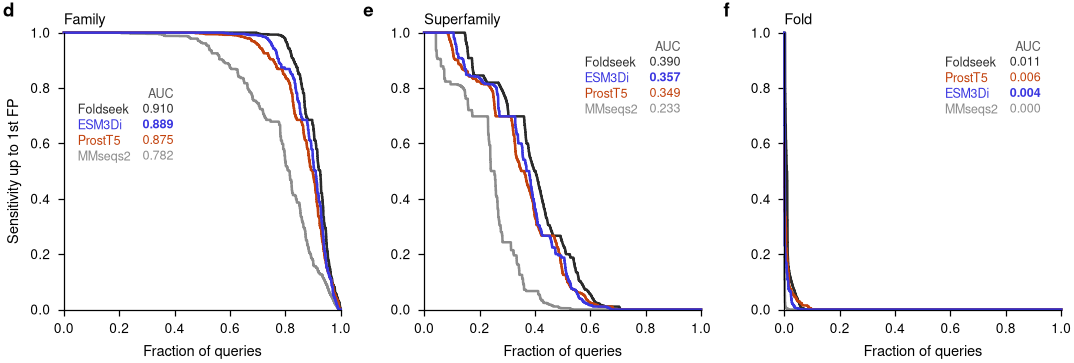

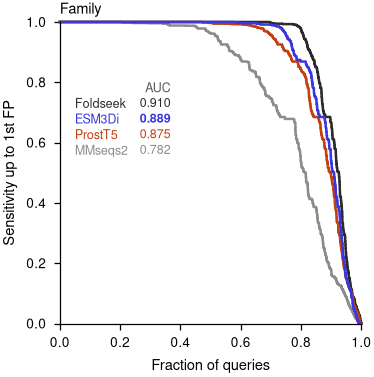

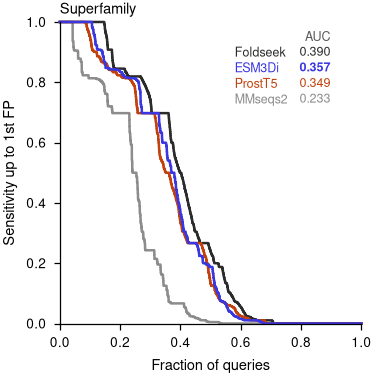

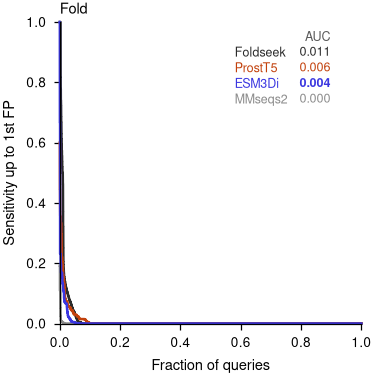

In [9]:
# Combined figure (full page width): one panel per SCOPe level, sharing the y axis label
fig, axes = plt.subplots(1, 3, figsize=(WIDTH_DOUBLE, 64 * MM), layout="constrained")
for i, (ax, level) in enumerate(zip(axes, SCOPE_LEVELS)):
    plot_scope_level(ax, scope_sensitivity, level, show_ylabel=i == 0)
add_panel_labels(axes, labels="def")  # follows panels a-c of the 3Di alignment figure
save_pub(fig, "scope_sensitivity_combined", FIG_DIR)
plt.show()

# One figure per SCOPe level
for level, suffix in SCOPE_LEVELS.items():
    fig, ax = plt.subplots(figsize=(65 * MM, 65 * MM), layout="constrained")
    plot_scope_level(ax, scope_sensitivity, level)
    save_pub(fig, f"scope_sensitivity_{level.lower()}", FIG_DIR)
    plt.show()